# Notebook 8: Close the loop (audit, random encoder in the hedger, methodology metrics)

This notebook uses the **same hedger and data pipeline as Notebook 7**, which reproduced Buehler's benchmark. It does not yet follow the methodology chapter's exact protocol (that is the next notebook). Its job is to settle the open questions from the pilot results first.

## Questions this notebook answers
| # | Question | Where |
|---|---|---|
| Q1 | Do our pilot settings and the methodology's settings actually agree? Is the probe label aligned with the context window? | Section 3 |
| Q2 | How do the existing saved hedgers score on the methodology's metrics (CVaR95, CVaR99)? No retraining. | Section 3 |
| Q3 | Is the untrained encoder really as good as JEPA (several random initialisations, optional JEPA retrains), on both $V$ and $\sqrt V$? Is the embedding collapsed? Where do the probe errors sit? | Section 5 |
| Q4 | **Does the random encoder, put into the hedger, hedge as well as JEPA?** (never tested before) | Section 7 to 8 |
| Q5 | Does any learned representation improve hedging over the raw window or realised variance? Per-seed paired statistics, gap closed against the raw-window floor (primary) and against `novol` (secondary) | Section 8 |
| Q6 | How precise must a variance estimate be to help hedging? (noisy-oracle sweep, `CONDITION_SET = 'all'`) | Section 8 |

## Framing to keep in mind
- **`novol` is a partial-information baseline, not "no hedge".** It sees $\log S_k$ and time to maturity, plus the variance swap as a tradable instrument, and already removes about 75% of the unhedged CVaR. JEPA has to beat a decent policy, not nothing.
- **Variance-swap level excluded from the state** in every condition here, because $L_t$ is an invertible function of $V_t$ given the accumulated integral and would leak it (the `withL` result in Notebook 6 showed this).
- **R² is average fidelity; CVaR is tail sensitivity.** A 0.76 probe can be useless for hedging if its errors sit where hedging matters. Section 5 shows errors by variance decile.
- **Decision rules below were written after the pilot results (Notebooks 6 and 7) were seen.** They govern the *confirmatory* run, not this pilot. Anything here is exploratory.

## Decision rules for the confirmatory run (fixed now; not to be changed after seeing results)
1. **Methodology gate (RO1):** oracle beats raw window by at least 20% in CVaR95 (mean over seeds).
2. **Methodology H2:** JEPA reduces CVaR95 by at least 10% relative to the strongest competitor (chosen on *validation* paths), and the paired permutation test is significant after Bonferroni correction.
3. **Pilot win condition used here:** mean gap closed (vs raw window) of at least 10% across at least 3 seeds, with the seed-bootstrap interval excluding zero.
4. **Null:** mean gap closed within +/-2% of zero with the interval containing zero. We commit to reporting that.
5. **Branches:** if `noisy_1.0` is about equal to `novol`, precision is the limit; if `random_*` is about equal to `jepa_*`, the input window is doing the work; if `*_z` beats `*_v`, the probe scalar was the bottleneck.

## A statistical limit that matters
An exact sign-flip permutation test on $n$ per-seed differences has minimum two-sided p-value $2/2^n$: **0.25 for 3 seeds, 0.0625 for 5, 0.0078 for 8**. The methodology's Bonferroni threshold (0.0083) is unreachable below 8 seeds. With fewer seeds, this notebook's p-values are descriptive only.

In [1]:
import sys, os, time, json, re, itertools
sys.path.insert(0, '..')
REPO_ROOT = os.path.join('..', 'deep-hedging-heston')
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import numpy as np
import torch, torch.nn as nn
from torch.utils.data import DataLoader
from sklearn.linear_model import Ridge
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm

from heston_sim.generate import load_split
from jepa.dataset import HestonWindowDataset
from jepa.model import HestonJEPA
from deep_hedging_heston.parameters import HestonParameters
from deep_hedging_heston.pricers import heston_call_deltas, model_deltas_on_paths
from deep_hedging_heston.simulate import MarketPaths, simulate_market

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
RESULTS = '../results'
RUNS = os.path.join(RESULTS, 'p8_runs')
os.makedirs(RUNS, exist_ok=True)
print('Device:', DEVICE)

C:\Users\USER\AppData\Roaming\Python\Python310\site-packages\google\api_core\_python_version_support.py:223: FutureWarning: You are using a non-supported Python version (3.10.20). Google will not post any further updates to google.api_core supporting this Python version. Please upgrade to the latest Python version, or at least Python 3.11, and then update google.api_core.
  warnings.warn(message, FutureWarning)


Device: cuda


In [2]:
# ---------------- configuration ----------------
PROFILE = 'quick'             # 'quick': 3000 steps x 3 seeds   |   'full': 15000 steps x 5 seeds
if PROFILE == 'quick':
    N_STEPS, SEEDS = 3000, [0, 1, 2]
else:
    N_STEPS, SEEDS = 15_000, [0, 1, 2, 3, 4]

CONDITION_SET = 'core'        # 'core' (8 conditions) or 'all' (adds ewma and the noisy-oracle sweep)
NOISE_MULTS = [0.25, 0.5, 1.0]
ALPHA_TRAIN = 0.5             # CVaR level used for TRAINING (methodology and Buehler: 0.5)
EVAL_ALPHAS = [0.5, 0.75, 0.9, 0.95, 0.99]
BATCH, LR = 1024, 1e-3
N_UNITS, N_LAYERS = 56, 2
W = 10                        # window = JEPA context of the existing checkpoint (methodology confirmatory: 15)
HT_PATHS, HT_SEED = 50_000, 77     # hedger-training paths (JEPA never saw them)
VA_PATHS, VA_SEED = 20_000, 88     # validation paths: competitor selection only
PROBE_PATHS = 30_000
N_RANDOM_INITS = 5            # random-encoder initialisations for the probe-R2 distribution
JEPA_RETRAIN_SEEDS = []       # e.g. [1, 2, 3] retrains JEPA with the existing recipe (several minutes per seed)
EWMA_LAMBDA = 0.94
BUEHLER_STD, BUEHLER_CVAR = 0.3808, 0.2433

CORE = ['oracle', 'novol', 'raw_window', 'rv', 'jepa_v', 'jepa_z', 'random_v', 'random_z']
CONDITIONS = CORE if CONDITION_SET == 'core' else CORE + ['ewma'] + [f'noisy_{m}' for m in NOISE_MULTS]
print(f'PROFILE={PROFILE} steps={N_STEPS} seeds={SEEDS}')
print('conditions:', CONDITIONS)

PROFILE=quick steps=3000 seeds=[0, 1, 2]
conditions: ['oracle', 'novol', 'raw_window', 'rv', 'jepa_v', 'jepa_z', 'random_v', 'random_z']


## 1. Helpers (pure numpy)

In [3]:
from scipy.special import ndtr
from numpy.lib.stride_tricks import sliding_window_view

def prior_variance(t):
    return hp.theta + (hp.v0 - hp.theta) * np.exp(-hp.kappa * hp.dt * t)

def est_rv(log_returns, w):
    N, T_ = log_returns.shape
    cs = np.concatenate([np.zeros((N, 1)), np.cumsum(log_returns.astype(np.float64) ** 2, axis=1)], axis=1)
    out = np.empty((N, T_ + 1), dtype=np.float32)
    for t in range(T_ + 1):
        out[:, t] = (cs[:, t] - cs[:, t - w]) / (w * hp.dt) if t >= w else prior_variance(t)
    return out

def est_ewma(log_returns, lam):
    N, T_ = log_returns.shape
    out = np.empty((N, T_ + 1), dtype=np.float32); out[:, 0] = hp.v0
    for t in range(1, T_ + 1):
        out[:, t] = lam * out[:, t - 1] + (1 - lam) * (log_returns[:, t - 1].astype(np.float64) ** 2) / hp.dt
    return out

def window_features(log_returns, w, scale):
    N, T_ = log_returns.shape
    rp = np.concatenate([np.zeros((N, w), dtype=np.float32), log_returns.astype(np.float32)], axis=1)
    return (sliding_window_view(rp, w, axis=1) / scale).astype(np.float32)

def corr2(a, b):
    if np.std(a) < 1e-12 or np.std(b) < 1e-12:
        return 0.0
    return float(np.corrcoef(a, b)[0, 1] ** 2)

def cvar_np(Wt, alpha=0.5):
    L = -np.asarray(Wt); k = int(alpha * len(L))
    return float(np.partition(L, k)[k:].mean())

def signflip_p(d):
    # exact two-sided sign-flip permutation test on per-seed differences
    d = np.asarray(d, dtype=float); n = len(d)
    signs = np.array(list(itertools.product([-1.0, 1.0], repeat=n)))
    return float((np.abs((signs * d).mean(1)) >= abs(d.mean()) - 1e-12).mean())

def min_attainable_p(n):
    return 2.0 / 2 ** n

def seed_boot_ci(d, B=5000, seed=0):
    d = np.asarray(d, dtype=float); rng = np.random.default_rng(seed)
    m = [d[rng.integers(0, len(d), len(d))].mean() for _ in range(B)]
    return float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))

def gap_closed(c_i, c_ref, c_oracle):
    den = c_ref - c_oracle
    return np.nan if den <= 1e-9 else (c_ref - c_i) / den

def features(cond, d, include_L=False):
    N = d['stocks'].shape[0]
    tau = np.broadcast_to((hp.T - hp.dt * np.arange(T)).astype(np.float32), (N, T))[:, :, None]
    blocks = [(np.log(d['stocks'][:, :T] / hp.S0)[:, :, None], False)]
    if cond == 'oracle':
        blocks.append((d['variance'][:, :T, None], False))
    elif cond == 'raw_window':
        blocks.append((d['win'][:, :T, :], True))
    elif cond == 'jepa_z':
        blocks.append((d['z'][:, :T, :], True))
    elif cond == 'random_z':
        blocks.append((d['zr'][:, :T, :], True))
    elif cond != 'novol':
        blocks.append((d['est'][cond][:, :T, None], False))
    if include_L:
        blocks.append((d['variance_swap'][:, :T, None], False))
    blocks.append((tau, False))
    F = np.concatenate([b for b, _ in blocks], axis=-1).astype(np.float32)
    skip = np.concatenate([np.full(b.shape[-1], s) for b, s in blocks])
    return F, skip
print('helpers defined')

helpers defined


## 2. Data and parameters

In [4]:
hp = HestonParameters()
T = hp.timesteps
train_data = load_split('train', '../data')
test_data = load_split('test', '../data')

def make_set(stocks, variance, vswap, payoff):
    lr = np.diff(np.log(stocks.astype(np.float64)), axis=1).astype(np.float32)
    return dict(stocks=stocks.astype(np.float32), variance=variance.astype(np.float32),
                variance_swap=vswap.astype(np.float32), payoff=payoff.astype(np.float32), log_returns=lr)

def fresh_set(seed, n):
    p = simulate_market(hp, seed=seed, nr_of_simulated_paths=n)
    return make_set(p.Stocks, p.Variance, p.Variance_swap, p.Payoff)

HT = fresh_set(HT_SEED, HT_PATHS)          # same seed as Notebook 7, so its caches are reused
VA = fresh_set(VA_SEED, VA_PATHS)
TE = make_set(test_data['stocks'], test_data['variance'], test_data['variance_swap'], test_data['payoff'])
R_SD = float(train_data['log_returns'].std())
print('paths: HT', HT['stocks'].shape, ' VA', VA['stocks'].shape, ' TE', TE['stocks'].shape)

paths: HT (50000, 31)  VA (20000, 31)  TE (50000, 31)


## 3. Audit (no training)
### 3a. Do the pilot parameters match the methodology chapter?

In [5]:
METH = dict(S0=100, v0=0.04, kappa=1.0, theta=0.04, xi=2.0, rho=-0.7, K=100, timesteps=30)
print(f'{"param":<10}{"ours":>10}{"methodology":>14}')
for k, v in METH.items():
    cur = getattr(hp, k)
    print(f'{k:<10}{cur:>10}{v:>14}   {"" if abs(cur - v) < 1e-9 else "<-- MISMATCH"}')
print(f'T (days): {hp.T * 365:.2f}   (methodology: 30)')
print('Structural differences that remain regardless of parameters (see the plan): 30-step paths with no 20-return warm-up,')
print('so the first W hedging dates have no full window; shared network with tau and previous holdings (methodology: one network per date, 2-17-17-2, BN, no previous holdings).')

param           ours   methodology
S0               100           100   
v0              0.04          0.04   
kappa            1.0           1.0   
theta           0.04          0.04   
xi               2.0           2.0   
rho             -0.7          -0.7   
K                100           100   
timesteps         30            30   
T (days): 30.00   (methodology: 30)
Structural differences that remain regardless of parameters (see the plan): 30-step paths with no 20-return warm-up,
so the first W hedging dates have no full window; shared network with tau and previous holdings (methodology: one network per date, 2-17-17-2, BN, no previous holdings).


### 3b. Is the probe label aligned with the context window?
A review note suggested the probe predicts $V_{t+5}$. The dataset code says the label is the variance at the end of the context window. This check verifies that numerically.

In [6]:
ds_chk = HestonWindowDataset(dict(log_returns=TE['log_returns'], variance=TE['variance']), W, 5, 'prices')
ok = True
for idx in [0, 7, 123, 4567, 40000]:
    s = ds_chk[idx]; p, t0 = int(s['path_idx']), int(s['t'])
    ctx_ok = np.allclose(s['context'].numpy()[:, 0], TE['log_returns'][p, t0:t0 + W])
    lab_ok = abs(float(s['target_variance']) - float(TE['variance'][p, t0 + W])) < 1e-9
    ok &= ctx_ok and lab_ok
    print(f'sample {idx:>6}: context = returns[{t0}:{t0 + W}] (last price index {t0 + W}), '
          f'label = V at index {t0 + W}   ctx_ok={ctx_ok} label_ok={lab_ok}')
print('ALIGNED: label is V at the last observed price, not V five steps later.' if ok else 'MISALIGNED: investigate')

sample      0: context = returns[0:10] (last price index 10), label = V at index 10   ctx_ok=True label_ok=True
sample      7: context = returns[7:17] (last price index 17), label = V at index 17   ctx_ok=True label_ok=True
sample    123: context = returns[11:21] (last price index 21), label = V at index 21   ctx_ok=True label_ok=True
sample   4567: context = returns[7:17] (last price index 17), label = V at index 17   ctx_ok=True label_ok=True
sample  40000: context = returns[0:10] (last price index 10), label = V at index 10   ctx_ok=True label_ok=True
ALIGNED: label is V at the last observed price, not V five steps later.


### 3c. Re-score the saved Notebook 7 hedgers on the methodology's metrics (CVaR95 / CVaR99), no retraining

In [7]:
NB7_RUNS = os.path.join(RESULTS, 'diag_runs')
pat = re.compile(r'^(?P<v>[^_]+)_(?P<c>.+)_s(?P<s>\d+)_n(?P<n>\d+)_W\.npy$')
found = {}
if os.path.isdir(NB7_RUNS):
    for f in sorted(os.listdir(NB7_RUNS)):
        m = pat.match(f)
        if m and m.group('v') == 'clean':
            found.setdefault((m.group('c'), int(m.group('n'))), []).append(np.load(os.path.join(NB7_RUNS, f)))
if not found:
    print('no Notebook 7 runs found; skipping')
else:
    print(f'{"condition":<14}{"steps":>7}{"seeds":>6}{"CVaR50":>9}{"CVaR95":>9}{"CVaR99":>9}{"std":>8}{"mean":>9}')
    for (c, n), ws in sorted(found.items(), key=lambda kv: np.mean([cvar_np(w, 0.95) for w in kv[1]])):
        print(f'{c:<14}{n:>7}{len(ws):>6}{np.mean([cvar_np(w,.5) for w in ws]):>9.4f}{np.mean([cvar_np(w,.95) for w in ws]):>9.4f}'
              f'{np.mean([cvar_np(w,.99) for w in ws]):>9.4f}{np.mean([w.std() for w in ws]):>8.4f}{np.mean([w.mean() for w in ws]):>+9.4f}')
    print('(mean terminal wealth should be near 0 for every hedged condition: a P&L sanity check)')

condition       steps seeds   CVaR50   CVaR95   CVaR99     std     mean
oracle           3000     1   0.2556   1.0152   1.7200  0.3937  -0.0017
iv               3000     1   0.2584   1.0273   1.7490  0.3968  -0.0018
noisy_oracle     3000     1   0.3332   1.2982   2.0458  0.5209  -0.0022
ewma             3000     1   0.3392   1.3887   2.2190  0.5465  -0.0036
rv               3000     1   0.3503   1.4084   2.2408  0.5572  -0.0035
jepa_v           3000     1   0.3504   1.4106   2.2359  0.5570  -0.0032
novol            3000     1   0.3612   1.4688   2.4088  0.5803  -0.0025
jepa_z           3000     1   0.3677   1.5356   2.4867  0.5954  -0.0028
raw_window       3000     1   0.3571   1.5594   2.5892  0.5881  -0.0037
(mean terminal wealth should be near 0 for every hedged condition: a P&L sanity check)


## 4. Encoders: trained JEPA and an untrained random encoder
Both pass through the same code. Embeddings are cached on disk.

In [8]:
ckpt = torch.load('../checkpoints/jepa_prices.pt', map_location=DEVICE, weights_only=False)
cfg = ckpt['config']
assert cfg['context_len'] == W, 'W must equal the JEPA context length'
D = cfg['d_model']

def new_jepa():
    return HestonJEPA(feature_dim=cfg['feature_dim'], d_model=D, n_heads=cfg['n_heads'], n_layers=cfg['n_layers'],
                      ema_momentum=cfg['ema_momentum'], var_reg_coeff=cfg['var_reg_coeff']).to(DEVICE)

jepa = new_jepa(); jepa.load_state_dict(ckpt['model_state']); jepa.eval()
torch.manual_seed(1000); rand0 = new_jepa(); rand0.eval()       # untrained, frozen

def encode_all(model, log_returns, bs=4096):
    N, T_ = log_returns.shape
    Z = np.zeros((N, T_ + 1, D), dtype=np.float32)
    for t in tqdm(range(W, T_ + 1), desc='encoding', leave=False):
        ctx = log_returns[:, t - W:t][:, :, None]
        for s in range(0, N, bs):
            Z[s:s + bs, t] = model.encode(torch.tensor(ctx[s:s + bs], dtype=torch.float32).to(DEVICE)).cpu().numpy()
    return Z

def get_z(model, tag, log_returns):
    p = os.path.join(RESULTS, f'z_{tag}.npy')
    if os.path.exists(p):
        Z = np.load(p)
        if Z.shape[0] == log_returns.shape[0]:
            print('loaded cached', tag); return Z
    Z = encode_all(model, log_returns); np.save(p, Z); return Z

psub = np.random.default_rng(42).choice(train_data['log_returns'].shape[0], PROBE_PATHS, replace=False)
PTR = dict(log_returns=train_data['log_returns'][psub], variance=train_data['variance'][psub])

Zj_ptr = get_z(jepa,  f'probe_train_n{PROBE_PATHS}', PTR['log_returns'])
Zr_ptr = get_z(rand0, f'rand0_probe_train_n{PROBE_PATHS}', PTR['log_returns'])
Zj, Zr = {}, {}
for name, d, tag in [('ht', HT, f'ht_s{HT_SEED}_n{HT_PATHS}'), ('va', VA, f'va_s{VA_SEED}_n{VA_PATHS}'), ('te', TE, 'te')]:
    Zj[name] = get_z(jepa,  tag, d['log_returns'])
    Zr[name] = get_z(rand0, f'rand0_{tag}', d['log_returns'])

def fit_probe(Zp, y_full):
    Ztr = Zp[:, W:, :].reshape(-1, D); y = y_full[:, W:].reshape(-1)
    sc = StandardScaler().fit(Ztr); rg = Ridge(alpha=1.0).fit(sc.transform(Ztr), y)
    return sc, rg

zs_j, rg_j = fit_probe(Zj_ptr, PTR['variance'])
zs_r, rg_r = fit_probe(Zr_ptr, PTR['variance'])

def make_vhat(Z, sc, rg):
    N = Z.shape[0]; out = np.empty((N, T + 1), dtype=np.float32)
    out[:, W:] = np.clip(rg.predict(sc.transform(Z[:, W:, :].reshape(-1, D))).reshape(N, -1), 0, None)
    out[:, :W] = prior_variance(np.arange(W))[None, :]
    return out

def std_z(Z, sc):
    Zs = ((Z - sc.mean_) / sc.scale_).astype(np.float32); Zs[:, :W, :] = 0.0
    return Zs

for name, d in [('ht', HT), ('va', VA), ('te', TE)]:
    d['z'] = std_z(Zj[name], zs_j); d['zr'] = std_z(Zr[name], zs_r)
    d['win'] = window_features(d['log_returns'], W, R_SD)
    d['est'] = {'rv': est_rv(d['log_returns'], W), 'ewma': est_ewma(d['log_returns'], EWMA_LAMBDA),
                'jepa_v': make_vhat(Zj[name], zs_j, rg_j), 'random_v': make_vhat(Zr[name], zs_r, rg_r)}

NOISE_SD = float(np.std((HT['est']['jepa_v'] - HT['variance'])[:, W:]))
rng = np.random.default_rng(123)
for d in (HT, VA, TE):
    for m in NOISE_MULTS:
        nz = np.clip(d['variance'] + m * NOISE_SD * rng.standard_normal(d['variance'].shape), 0, None).astype(np.float32)
        nz[:, :W] = prior_variance(np.arange(W))[None, :]
        d['est'][f'noisy_{m}'] = nz
print(f'JEPA residual sd on hedger-training paths: {NOISE_SD:.5f}  (mean V = {HT["variance"].mean():.5f})')
del Zj, Zr, Zj_ptr, Zr_ptr

c:\Users\USER\OneDrive\Desktop\IIT\Thesis\Implementation\Git Repo\JEPA---Deep-Hedging\Vibe coded experiment 2\Jepa-Heston\notebooks\..\jepa\encoder.py:94: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


loaded cached probe_train_n30000


encoding:   0%|          | 0/21 [00:00<?, ?it/s]

loaded cached ht_s77_n50000


encoding:   0%|          | 0/21 [00:00<?, ?it/s]

encoding:   0%|          | 0/21 [00:00<?, ?it/s]

encoding:   0%|          | 0/21 [00:00<?, ?it/s]

loaded cached te


encoding:   0%|          | 0/21 [00:00<?, ?it/s]

JEPA residual sd on hedger-training paths: 0.04354  (mean V = 0.03933)


## 5. Representation diagnostics (Q3)
### 5a. Probe table: V and sqrt(V) targets, linear and MLP probes, test paths, t >= W

In [9]:
NP = 20_000
def pool(arr, y):
    return arr[:NP, W:, :].reshape(-1, arr.shape[-1]), y[:NP, W:].reshape(-1)

def fit_eval(Xa, ya, Xb, yb, mlp=False):
    sc = StandardScaler().fit(Xa)
    m = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=60, early_stopping=True, random_state=0) if mlp else Ridge(alpha=1.0)
    if mlp:
        idx = np.random.default_rng(0).choice(len(Xa), min(120_000, len(Xa)), replace=False)
        m.fit(sc.transform(Xa[idx]), ya[idx])
    else:
        m.fit(sc.transform(Xa), ya)
    return r2_score(yb, m.predict(sc.transform(Xb)))

# window and z features for the probe-train subset (first NP paths) and test subset
Wp = window_features(PTR['log_returns'][:NP], W, R_SD)
Zj_p = np.load(os.path.join(RESULTS, f'z_probe_train_n{PROBE_PATHS}.npy'))[:NP]
Zr_p = np.load(os.path.join(RESULTS, f'z_rand0_probe_train_n{PROBE_PATHS}.npy'))[:NP]
Zj_t = np.load(os.path.join(RESULTS, 'z_te.npy'))[:NP]
Zr_t = np.load(os.path.join(RESULTS, 'z_rand0_te.npy'))[:NP]

reps = {'raw window (15->W returns), linear': (Wp, window_features(TE['log_returns'][:NP], W, R_SD), False),
        'raw window squared, linear': (Wp ** 2, window_features(TE['log_returns'][:NP], W, R_SD) ** 2, False),
        'random encoder, linear': (Zr_p, Zr_t, False), 'JEPA, linear': (Zj_p, Zj_t, False),
        'random encoder, MLP': (Zr_p, Zr_t, True), 'JEPA, MLP': (Zj_p, Zj_t, True)}
print(f'{"representation":<36}{"R2 on V":>10}{"R2 on sqrt(V)":>16}')
probe_rows = {}
for nm, (A, B, mlp) in reps.items():
    r = []
    for tgt in (lambda v: v, np.sqrt):
        Xa, ya = pool(A, tgt(PTR['variance'])); Xb, yb = pool(B, tgt(TE['variance']))
        r.append(fit_eval(Xa, ya, Xb, yb, mlp))
    probe_rows[nm] = r; print(f'{nm:<36}{r[0]:>10.3f}{r[1]:>16.3f}')
rvp = TE['est']['rv'][:NP, W:].reshape(-1); Vp = TE['variance'][:NP, W:].reshape(-1)
print(f'{"annualised realised variance":<36}{r2_score(Vp, rvp):>10.3f}{r2_score(np.sqrt(Vp), np.sqrt(np.clip(rvp, 0, None))):>16.3f}   (no fitting)')

representation                         R2 on V   R2 on sqrt(V)
raw window (15->W returns), linear       0.263           0.192
raw window squared, linear               0.691           0.619


C:\Users\USER\AppData\Roaming\Python\Python310\site-packages\sklearn\linear_model\_ridge.py:213: LinAlgWarning: Ill-conditioned matrix (rcond=6.3788e-09): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
C:\Users\USER\AppData\Roaming\Python\Python310\site-packages\sklearn\linear_model\_ridge.py:213: LinAlgWarning: Ill-conditioned matrix (rcond=6.3788e-09): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


random encoder, linear                   0.777           0.781
JEPA, linear                             0.756           0.718
random encoder, MLP                      0.790           0.881
JEPA, MLP                                0.781           0.880
annualised realised variance             0.660           0.738   (no fitting)


### 5b. Is "random beats JEPA" real? Several random initialisations (and optional JEPA retrains)

In [10]:
def probe_r2_for(model):
    ztr = encode_all(model, PTR['log_returns'][:NP]); zte = encode_all(model, TE['log_returns'][:NP])
    Xa, ya = pool(ztr, PTR['variance']); Xb, yb = pool(zte, TE['variance'])
    return fit_eval(Xa, ya, Xb, yb)

rand_r2 = []
for i in range(N_RANDOM_INITS):
    torch.manual_seed(2000 + i); m = new_jepa(); m.eval(); rand_r2.append(probe_r2_for(m))
    print(f'random init {i}: linear-probe R2 on V = {rand_r2[-1]:.3f}')
jepa_r2 = probe_r2_for(jepa)
print(f'\nrandom encoders: mean {np.mean(rand_r2):.3f}  sd {np.std(rand_r2):.3f}  range [{min(rand_r2):.3f}, {max(rand_r2):.3f}]')
print(f'trained JEPA (existing checkpoint): {jepa_r2:.3f}')

JEPA_R2_RETRAIN = []
if JEPA_RETRAIN_SEEDS:
    JTR = dict(log_returns=train_data['log_returns'][:50_000], variance=train_data['variance'][:50_000])
    def train_jepa(seed, epochs=30, bs=512, lr=3e-4):
        torch.manual_seed(seed); np.random.seed(seed)
        ld = DataLoader(HestonWindowDataset(JTR, W, 5, 'prices'), batch_size=bs, shuffle=True)
        m = new_jepa()
        opt = torch.optim.AdamW([p for p in m.parameters() if p.requires_grad], lr=lr, weight_decay=1e-4)
        sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
        for ep in tqdm(range(epochs), desc=f'JEPA seed {seed}'):
            m.train()
            for b in ld:
                loss, _, _ = m(b['context'].to(DEVICE), b['target'].to(DEVICE))
                opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step(); m.ema_update()
            sch.step()
        m.eval(); return m
    for s in JEPA_RETRAIN_SEEDS:
        JEPA_R2_RETRAIN.append(probe_r2_for(train_jepa(s)))
        print(f'JEPA retrain seed {s}: linear-probe R2 = {JEPA_R2_RETRAIN[-1]:.3f}')
    print(f'retrained JEPA: mean {np.mean(JEPA_R2_RETRAIN):.3f}  sd {np.std(JEPA_R2_RETRAIN):.3f}')
else:
    print('\n(set JEPA_RETRAIN_SEEDS = [1, 2, 3] to retrain JEPA and compare distributions; that is the fair test of "does training help")')

c:\Users\USER\OneDrive\Desktop\IIT\Thesis\Implementation\Git Repo\JEPA---Deep-Hedging\Vibe coded experiment 2\Jepa-Heston\notebooks\..\jepa\encoder.py:94: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


encoding:   0%|          | 0/21 [00:00<?, ?it/s]

encoding:   0%|          | 0/21 [00:00<?, ?it/s]

C:\Users\USER\AppData\Roaming\Python\Python310\site-packages\sklearn\linear_model\_ridge.py:213: LinAlgWarning: Ill-conditioned matrix (rcond=1.41034e-08): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


random init 0: linear-probe R2 on V = 0.780


c:\Users\USER\OneDrive\Desktop\IIT\Thesis\Implementation\Git Repo\JEPA---Deep-Hedging\Vibe coded experiment 2\Jepa-Heston\notebooks\..\jepa\encoder.py:94: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


... (16 outputs left out)

random init 4: linear-probe R2 on V = 0.771


encoding:   0%|          | 0/21 [00:00<?, ?it/s]

encoding:   0%|          | 0/21 [00:00<?, ?it/s]


random encoders: mean 0.768  sd 0.027  range [0.715, 0.792]
trained JEPA (existing checkpoint): 0.756

(set JEPA_RETRAIN_SEEDS = [1, 2, 3] to retrain JEPA and compare distributions; that is the fair test of "does training help")


### 5c. Embedding collapse check and where the probe errors sit

trained JEPA    sd_min=0.0001331  sd_median=0.0007696  sd_max=0.002269  top1_share=0.9476  eff_rank=1.113  eff_rank_standardised=1.607
random encoder  sd_min=0.0003558  sd_median=0.002001  sd_max=0.006335  top1_share=0.9703  eff_rank=1.062  eff_rank_standardised=1.542
(out of 64 dimensions; the methodology flags effective rank below 10/32 as collapse)

RMSE of each estimate by decile of true V (decile 9 = highest variance):
estimator       d0      d1      d2      d3      d4      d5      d6      d7      d8      d9
jepa_v      0.0114  0.0112  0.0113  0.0114  0.0113  0.0115  0.0237  0.0353  0.0506  0.1194
random_v    0.0091  0.0089  0.0090  0.0090  0.0090  0.0092  0.0231  0.0360  0.0511  0.1125
rv          0.0130  0.0129  0.0130  0.0131  0.0130  0.0134  0.0326  0.0475  0.0641  0.1380


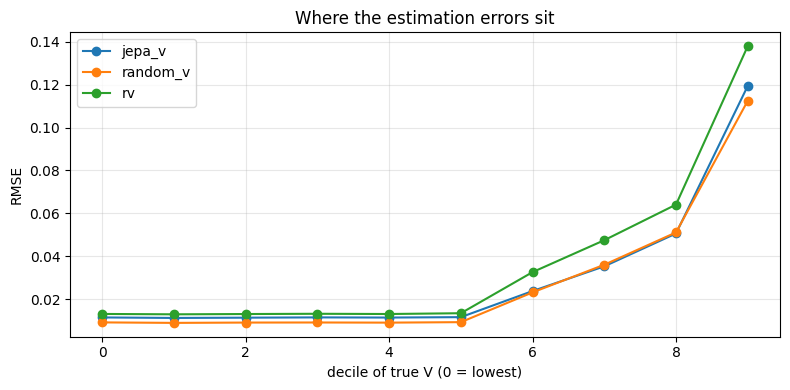

In [11]:
def collapse_stats(Z):
    X = Z[:NP, W:, :].reshape(-1, Z.shape[-1]).astype(np.float64); sd = X.std(0)
    ev = np.clip(np.linalg.eigvalsh(np.cov(X.T)), 0, None)
    Xs = (X - X.mean(0)) / (sd + 1e-12); evs = np.clip(np.linalg.eigvalsh(np.cov(Xs.T)), 0, None)
    return dict(sd_min=sd.min(), sd_median=float(np.median(sd)), sd_max=sd.max(), top1_share=float(ev.max() / ev.sum()),
                eff_rank=float(ev.sum() ** 2 / (ev ** 2).sum()), eff_rank_standardised=float(evs.sum() ** 2 / (evs ** 2).sum()))
for nm, Z in [('trained JEPA', Zj_t), ('random encoder', Zr_t)]:
    print(f'{nm:15s} ' + '  '.join(f'{k}={v:.4g}' for k, v in collapse_stats(Z).items()))
print(f'(out of {D} dimensions; the methodology flags effective rank below 10/32 as collapse)')

# residuals by true-variance decile (test paths, t >= W)
V = TE['variance'][:, W:].reshape(-1)
edges = np.quantile(V, np.linspace(0, 1, 11)); bins = np.clip(np.digitize(V, edges[1:-1]), 0, 9)
print('\nRMSE of each estimate by decile of true V (decile 9 = highest variance):')
print(f'{"estimator":<10}' + ''.join(f'{"d" + str(i):>8}' for i in range(10)))
fig, ax = plt.subplots(figsize=(8, 4))
for nm in ['jepa_v', 'random_v', 'rv']:
    e = TE['est'][nm][:, W:].reshape(-1) - V
    rm = [float(np.sqrt(np.mean(e[bins == i] ** 2))) for i in range(10)]
    print(f'{nm:<10}' + ''.join(f'{x:>8.4f}' for x in rm)); ax.plot(range(10), rm, marker='o', label=nm)
ax.set_xlabel('decile of true V (0 = lowest)'); ax.set_ylabel('RMSE'); ax.legend(); ax.grid(alpha=0.3)
ax.set_title('Where the estimation errors sit'); plt.tight_layout()
plt.savefig(os.path.join(RESULTS, 'p8_residual_by_decile.png'), dpi=150); plt.show()
del Zj_t, Zr_t, Zj_p, Zr_p, Wp

## 6. Benchmarks (test set)

In [12]:
price0, _, _ = heston_call_deltas(np.array([hp.S0]), np.array([hp.v0]), hp.T, hp)
PREMIUM = float(price0[0])
dS_np = {k: (d['stocks'][:, 1:] - d['stocks'][:, :-1]).astype(np.float64) for k, d in [('ht', HT), ('va', VA), ('te', TE)]}
dL_np = {k: (d['variance_swap'][:, 1:] - d['variance_swap'][:, :-1]).astype(np.float64) for k, d in [('ht', HT), ('va', VA), ('te', TE)]}
D2_SCALE = float(dS_np['ht'].std() / dL_np['ht'].std())

W_unhedged = PREMIUM - TE['payoff']
p_an = os.path.join(RESULTS, 'w_analytical_te.npy')
if os.path.exists(p_an):
    W_analytical = np.load(p_an)
else:
    mkt = MarketPaths(Stocks=TE['stocks'], Variance=TE['variance'], Variance_swap=TE['variance_swap'], Payoff=TE['payoff'])
    d1_an, d2_an = model_deltas_on_paths(mkt, hp)
    W_analytical = PREMIUM + (d1_an * dS_np['te'] + d2_an * dL_np['te']).sum(1) - TE['payoff']; np.save(p_an, W_analytical)
print(f'premium {PREMIUM:.4f}   D2_SCALE {D2_SCALE:.1f}')
print(f'{"":<11}{"CVaR50":>9}{"CVaR95":>9}{"CVaR99":>9}{"std":>8}{"mean":>9}')
for nm, Wt in [('unhedged', W_unhedged), ('analytical', W_analytical)]:
    print(f'{nm:<11}{cvar_np(Wt,.5):>9.4f}{cvar_np(Wt,.95):>9.4f}{cvar_np(Wt,.99):>9.4f}{Wt.std():>8.4f}{Wt.mean():>+9.4f}')
print(f'Buehler ref: std={BUEHLER_STD} CVaR50={BUEHLER_CVAR}')

premium 1.6918   D2_SCALE 1026.8
              CVaR50   CVaR95   CVaR99     std     mean
unhedged      1.4718   6.7010  11.0826  2.1635  +0.0005
analytical    0.2412   0.9522   1.6238  0.3739  -0.0021
Buehler ref: std=0.3808 CVaR50=0.2433


## 7. Hedger (identical to Notebooks 6 and 7) and training

In [13]:
class Hedger(nn.Module):
    def __init__(self, in_dim, d2_scale, n_units=N_UNITS, n_layers=N_LAYERS):
        super().__init__()
        layers = [nn.Linear(in_dim + 2, n_units), nn.Tanh()]
        for _ in range(n_layers - 1):
            layers += [nn.Linear(n_units, n_units), nn.Tanh()]
        layers += [nn.Linear(n_units, 2)]
        self.net = nn.Sequential(*layers); self.d2_scale = d2_scale; self.w = nn.Parameter(torch.zeros(()))
    def forward(self, x, prev_raw):
        raw = self.net(torch.cat([x, prev_raw], dim=-1))
        return raw, torch.stack([raw[:, 0], raw[:, 1] * self.d2_scale], dim=-1)

def terminal_wealth(net, X, dS, dL, payoff):
    N, T_, _ = X.shape
    prev = torch.zeros(N, 2, device=X.device); pnl = torch.zeros(N, device=X.device)
    for t in range(T_):
        raw, d = net(X[:, t, :], prev)
        pnl = pnl + d[:, 0] * dS[:, t] + d[:, 1] * dL[:, t]; prev = raw
    return PREMIUM + pnl - payoff

def cvar_loss(Wt, w, alpha):
    return w + torch.relu(-Wt - w).mean() / (1.0 - alpha)

def train_one(X, dS, dL, payoff, label, seed):
    torch.manual_seed(seed)
    net = Hedger(X.shape[-1], D2_SCALE).to(DEVICE)
    opt = torch.optim.Adam([{'params': net.net.parameters(), 'lr': LR}, {'params': [net.w], 'lr': 1e-2}])
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=N_STEPS)
    g = torch.Generator().manual_seed(seed); n = X.shape[0]; hist, run = [], []
    pbar = tqdm(range(N_STEPS), desc=label)
    for step in pbar:
        idx = torch.randint(0, n, (BATCH,), generator=g).to(DEVICE)       # same batches for every condition at a given seed
        loss = cvar_loss(terminal_wealth(net, X[idx], dS[idx], dL[idx], payoff[idx]), net.w, ALPHA_TRAIN)
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(net.parameters(), 1.0); opt.step(); sch.step()
        run.append(loss.item())
        if (step + 1) % 200 == 0:
            hist.append(float(np.mean(run))); run = []; pbar.set_postfix({'CVaR': f'{hist[-1]:.4f}'})
    return net, np.array(hist)

def eval_W(net, X, dS, dL, payoff, bs=25_000):
    net.eval(); out = []
    with torch.no_grad():
        for s in range(0, X.shape[0], bs):
            out.append(terminal_wealth(net, X[s:s+bs], dS[s:s+bs], dL[s:s+bs], payoff[s:s+bs]).cpu().numpy())
    return np.concatenate(out)

def to_t(a): return torch.tensor(np.ascontiguousarray(a), dtype=torch.float32, device=DEVICE)
print('defined')

defined


## 8. Run all conditions
Each model is saved to `results/p8_runs/`; re-running this cell **skips finished models**. Terminal wealth is stored for both validation (competitor selection) and test paths. The seed fixes the minibatch order, so conditions are paired by seed.

In [14]:
SETS = {'ht': HT, 'va': VA, 'te': TE}
tens = {k: (to_t(dS_np[k]), to_t(dL_np[k]), to_t(SETS[k]['payoff'])) for k in SETS}

for cond in CONDITIONS:
    todo = [s for s in SEEDS if not os.path.exists(os.path.join(RUNS, f'{cond}_s{s}_n{N_STEPS}_Wte.npy'))]
    if not todo:
        print('skip (done):', cond); continue
    Fh, skip = features(cond, HT); Fv, _ = features(cond, VA); Ft, _ = features(cond, TE)
    flat = Fh.reshape(-1, Fh.shape[-1]); mu, sd = flat.mean(0), flat.std(0) + 1e-8; mu[skip] = 0.0; sd[skip] = 1.0
    Xh, Xv, Xt = to_t((Fh - mu) / sd), to_t((Fv - mu) / sd), to_t((Ft - mu) / sd)
    del Fh, Fv, Ft, flat
    for seed in todo:
        key = f'{cond}_s{seed}_n{N_STEPS}'
        net, hist = train_one(Xh, *tens['ht'], key, seed)
        Wva = eval_W(net, Xv, *tens['va']); Wte = eval_W(net, Xt, *tens['te'])
        np.save(os.path.join(RUNS, key + '_Wva.npy'), Wva); np.save(os.path.join(RUNS, key + '_hist.npy'), hist)
        np.save(os.path.join(RUNS, key + '_Wte.npy'), Wte)
        print(f'{key}: test CVaR50={cvar_np(Wte,.5):.4f} CVaR95={cvar_np(Wte,.95):.4f} std={Wte.std():.4f} mean={Wte.mean():+.4f}')
    del Xh, Xv, Xt
    if DEVICE == 'cuda':
        torch.cuda.empty_cache()

oracle_s0_n3000:   0%|          | 0/3000 [00:00<?, ?it/s]

oracle_s0_n3000: test CVaR50=0.2556 CVaR95=1.0157 std=0.3938 mean=-0.0017


oracle_s1_n3000:   0%|          | 0/3000 [00:00<?, ?it/s]

oracle_s1_n3000: test CVaR50=0.2544 CVaR95=1.0136 std=0.3925 mean=-0.0015


oracle_s2_n3000:   0%|          | 0/3000 [00:00<?, ?it/s]

oracle_s2_n3000: test CVaR50=0.2563 CVaR95=1.0181 std=0.3963 mean=-0.0021


... (38 outputs left out)

random_z_s1_n3000:   0%|          | 0/3000 [00:00<?, ?it/s]

random_z_s1_n3000: test CVaR50=0.3692 CVaR95=1.5357 std=0.5929 mean=-0.0038


random_z_s2_n3000:   0%|          | 0/3000 [00:00<?, ?it/s]

random_z_s2_n3000: test CVaR50=0.3664 CVaR95=1.5286 std=0.5923 mean=-0.0030


## 9. Results

In [15]:
def load_all(cond, split):
    out = []
    for s in SEEDS:
        p = os.path.join(RUNS, f'{cond}_s{s}_n{N_STEPS}_W{split}.npy')
        if os.path.exists(p): out.append(np.load(p))
    return out

Wte = {c: load_all(c, 'te') for c in CONDITIONS}; Wte = {c: w for c, w in Wte.items() if w}
Wva = {c: load_all(c, 'va') for c in Wte}
n_seeds = min(len(w) for w in Wte.values())
print(f'seeds per condition: {[len(w) for w in Wte.values()]}   (minimum {n_seeds})')

cv = {c: {a: np.array([cvar_np(w, a) for w in ws]) for a in EVAL_ALPHAS} for c, ws in Wte.items()}
print(f'\n{"condition":<14}{"CVaR50":>16}{"CVaR95":>16}{"CVaR99":>16}{"std":>9}{"mean":>9}')
for c in sorted(Wte, key=lambda c: cv[c][0.95].mean()):
    f = lambda a: f'{cv[c][a].mean():.4f}+/-{cv[c][a].std():.4f}'
    print(f'{c:<14}{f(0.5):>16}{f(0.95):>16}{f(0.99):>16}{np.mean([w.std() for w in Wte[c]]):>9.4f}{np.mean([w.mean() for w in Wte[c]]):>+9.4f}')
for nm, Wt in [('analytical', W_analytical), ('unhedged', W_unhedged)]:
    print(f'{nm:<14}{cvar_np(Wt,.5):>16.4f}{cvar_np(Wt,.95):>16.4f}{cvar_np(Wt,.99):>16.4f}{Wt.std():>9.4f}{Wt.mean():>+9.4f}')

seeds per condition: [3, 3, 3, 3, 3, 3, 3, 3]   (minimum 3)

condition               CVaR50          CVaR95          CVaR99      std     mean
oracle         0.2554+/-0.0008 1.0158+/-0.0018 1.7235+/-0.0025   0.3942  -0.0017
random_v       0.3496+/-0.0006 1.4060+/-0.0029 2.2221+/-0.0092   0.5541  -0.0034
rv             0.3505+/-0.0008 1.4088+/-0.0025 2.2361+/-0.0098   0.5575  -0.0033
jepa_v         0.3508+/-0.0006 1.4146+/-0.0031 2.2424+/-0.0108   0.5576  -0.0031
novol          0.3628+/-0.0012 1.4783+/-0.0072 2.4250+/-0.0130   0.5834  -0.0024
random_z       0.3666+/-0.0021 1.5249+/-0.0107 2.5082+/-0.0267   0.5905  -0.0032
jepa_z         0.3673+/-0.0003 1.5388+/-0.0047 2.5092+/-0.0159   0.5964  -0.0022
raw_window     0.3560+/-0.0024 1.5595+/-0.0190 2.6022+/-0.0380   0.5887  -0.0037
analytical              0.2412          0.9522          1.6238   0.3739  -0.0021
unhedged                1.4718          6.7010         11.0826   2.1635  +0.0005


In [16]:
def per_seed(c, a=0.95): return cv[c][a][:n_seeds]
need = {'oracle', 'raw_window', 'novol'}
summary = {}
if need <= set(Wte):
    # ---- RO1 gate: oracle vs raw window ----
    for a in (0.95, 0.5):
        G = (per_seed('raw_window', a) - per_seed('oracle', a)) / per_seed('raw_window', a)
        lo, hi = seed_boot_ci(G)
        print(f'RO1 gate at CVaR{int(a*100)}: oracle beats raw window by {100*G.mean():.1f}%  seed CI [{100*lo:.1f}, {100*hi:.1f}]  ->  '
              f'{"PASS" if G.mean() >= 0.20 else "FAIL"} (threshold 20%)')
    G = (per_seed('novol') - per_seed('oracle')) / per_seed('novol')
    print(f'oracle beats novol by {100*G.mean():.1f}% (CVaR95)   |   novol already removes {100*(1-cv["novol"][0.95].mean()/cvar_np(W_unhedged,.95)):.1f}% of the unhedged CVaR95')

    # ---- strongest competitor chosen on VALIDATION paths only ----
    cands = [c for c in ('raw_window', 'rv', 'ewma') if c in Wva]
    va95 = {c: np.mean([cvar_np(w, 0.95) for w in Wva[c]]) for c in cands}
    best = min(va95, key=va95.get)
    print(f'\nstrongest competitor on validation CVaR95: {best}   ({ {k: round(v, 4) for k, v in va95.items()} })')

    # ---- gap closed, two references ----
    print(f'\n{"condition":<14}{"gap closed vs raw window (primary)":>40}{"gap closed vs novol (secondary)":>34}')
    for c in sorted(Wte):
        if c in ('oracle',): continue
        g1 = np.array([gap_closed(per_seed(c)[i], per_seed('raw_window')[i], per_seed('oracle')[i]) for i in range(n_seeds)])
        g2 = np.array([gap_closed(per_seed(c)[i], per_seed('novol')[i], per_seed('oracle')[i]) for i in range(n_seeds)])
        summary[c] = dict(gap_raw=float(np.nanmean(g1)), gap_novol=float(np.nanmean(g2)))
        print(f'{c:<14}{100*np.nanmean(g1):>+30.1f}% (sd {100*np.nanstd(g1):4.1f}){100*np.nanmean(g2):>+22.1f}% (sd {100*np.nanstd(g2):4.1f})')

RO1 gate at CVaR95: oracle beats raw window by 34.9%  seed CI [33.7, 36.0]  ->  PASS (threshold 20%)
RO1 gate at CVaR50: oracle beats raw window by 28.2%  seed CI [27.3, 29.0]  ->  PASS (threshold 20%)
oracle beats novol by 31.3% (CVaR95)   |   novol already removes 77.9% of the unhedged CVaR95

strongest competitor on validation CVaR95: rv   ({'raw_window': np.float64(1.5802), 'rv': np.float64(1.4069)})

condition           gap closed vs raw window (primary)   gap closed vs novol (secondary)
jepa_v                                 +26.5% (sd  2.9)                 +13.8% (sd  1.1)
jepa_z                                  +3.7% (sd  2.6)                 -13.1% (sd  1.3)
novol                                  +14.8% (sd  2.8)                  +0.0% (sd  0.0)
random_v                               +28.1% (sd  2.5)                 +15.6% (sd  0.8)
random_z                                +6.3% (sd  3.4)                 -10.1% (sd  0.7)
raw_window                              +0.0% (sd  0.0)  

In [17]:
# ---- paired per-seed comparisons on CVaR95 (positive difference = A better than B) ----
def paired(A, B, label, primary=False, n_bonf=6):
    d = per_seed(B) - per_seed(A); rel = d / per_seed(B)
    lo, hi = seed_boot_ci(d); p = signflip_p(d)
    padj = p if primary else min(1.0, p * n_bonf)
    print(f'{label:<52} diff {d.mean():+.4f} [{lo:+.4f},{hi:+.4f}]  rel {100*rel.mean():+6.1f}%  p={p:.3f} '
          f'{"" if primary else f"(Bonf {padj:.3f}) "}min-p={min_attainable_p(len(d)):.4f}')
    return dict(label=label, diff=float(d.mean()), lo=lo, hi=hi, rel=float(rel.mean()), p=p, p_adj=padj)

if need <= set(Wte):
    print(f'Paired comparisons, {n_seeds} seeds.  Exact sign-flip p has minimum {min_attainable_p(n_seeds):.4f}; '
          f'Bonferroni threshold is 0.0083 -> {"reachable" if min_attainable_p(n_seeds) < 0.0083 else "NOT reachable: descriptive only"}')
    tests = []
    if 'jepa_z' in Wte: tests.append(paired('jepa_z', best, f'PRIMARY  JEPA embedding vs {best}', primary=True))
    if 'jepa_v' in Wte: tests.append(paired('jepa_v', best, f'         JEPA scalar    vs {best}'))
    for a, b, lab in [('jepa_z', 'random_z', 'JEPA vs random encoder (embedding)'), ('jepa_v', 'random_v', 'JEPA vs random encoder (scalar)'),
                      ('jepa_z', 'jepa_v', 'JEPA embedding vs JEPA scalar (bottleneck)'), ('oracle', 'raw_window', 'oracle vs raw window')]:
        if a in Wte and b in Wte: tests.append(paired(a, b, lab))
    for c in ['jepa_z', 'jepa_v', 'random_z', 'random_v', 'raw_window', 'rv', 'ewma']:
        if c in Wte: tests.append(paired(c, 'novol', f'{c} vs novol'))
    for c in [x for x in Wte if x.startswith('noisy_')]:
        tests.append(paired(c, 'novol', f'{c} vs novol'))
        if 'jepa_v' in Wte: tests.append(paired('jepa_v', c, f'jepa_v vs {c}'))
    summary['paired'] = tests
    json.dump(summary, open(os.path.join(RESULTS, f'p8_summary_n{N_STEPS}.json'), 'w'), indent=1, default=float)

Paired comparisons, 3 seeds.  Exact sign-flip p has minimum 0.2500; Bonferroni threshold is 0.0083 -> NOT reachable: descriptive only
PRIMARY  JEPA embedding vs rv                        diff -0.1301 [-0.1392,-0.1227]  rel   -9.2%  p=0.250 min-p=0.2500
         JEPA scalar    vs rv                        diff -0.0058 [-0.0080,-0.0030]  rel   -0.4%  p=0.250 (Bonf 1.000) min-p=0.2500
JEPA vs random encoder (embedding)                   diff -0.0139 [-0.0259,-0.0063]  rel   -0.9%  p=0.250 (Bonf 1.000) min-p=0.2500
JEPA vs random encoder (scalar)                      diff -0.0085 [-0.0103,-0.0064]  rel   -0.6%  p=0.250 (Bonf 1.000) min-p=0.2500
JEPA embedding vs JEPA scalar (bottleneck)           diff -0.1243 [-0.1312,-0.1163]  rel   -8.8%  p=0.250 (Bonf 1.000) min-p=0.2500
oracle vs raw window                                 diff +0.5437 [+0.5183,+0.5693]  rel  +34.9%  p=0.250 (Bonf 1.000) min-p=0.2500
jepa_z vs novol                                      diff -0.0605 [-0.0673,-0.0551]  re

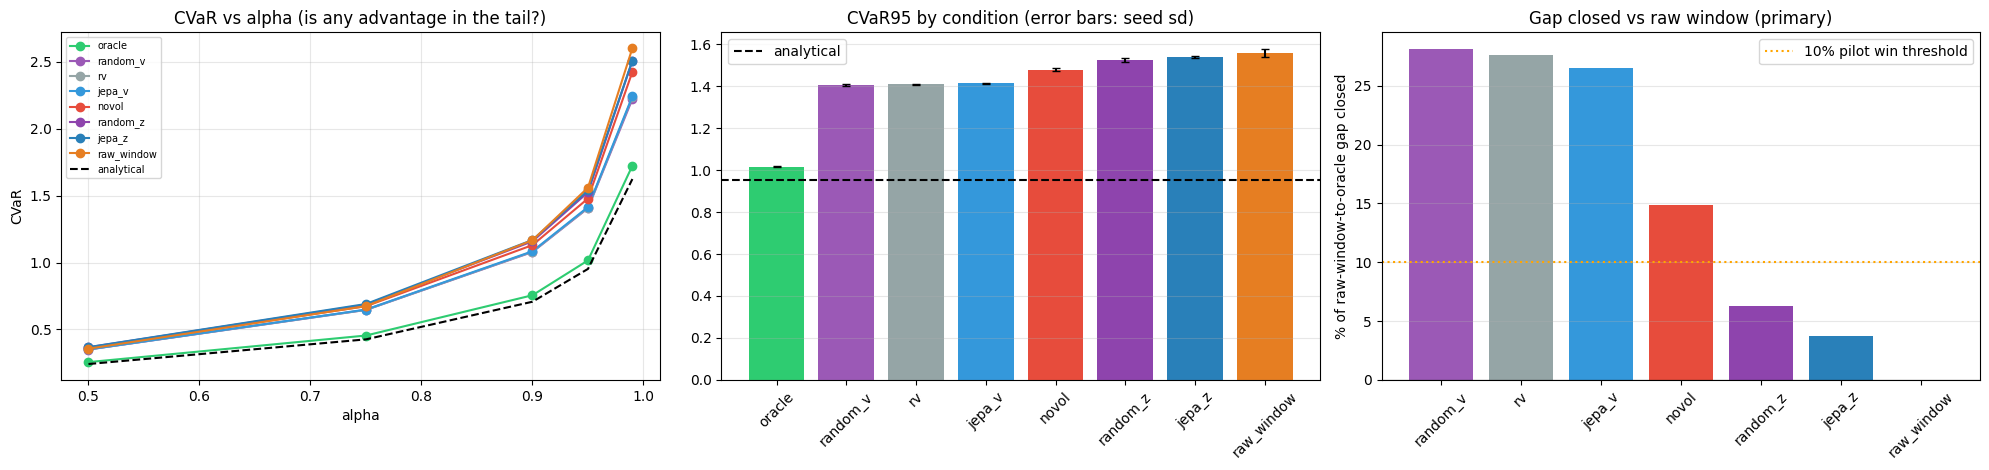

In [18]:
# ---- plots ----
colors = {'oracle': '#2ecc71', 'novol': '#e74c3c', 'raw_window': '#e67e22', 'rv': '#95a5a6', 'ewma': '#7f8c8d',
          'jepa_v': '#3498db', 'jepa_z': '#2980b9', 'random_v': '#9b59b6', 'random_z': '#8e44ad'}
fig, axes = plt.subplots(1, 3, figsize=(20, 4.8))
ax = axes[0]
for c in sorted(Wte, key=lambda c: cv[c][0.95].mean()):
    ax.plot(EVAL_ALPHAS, [cv[c][a].mean() for a in EVAL_ALPHAS], marker='o', label=c, color=colors.get(c))
ax.plot(EVAL_ALPHAS, [cvar_np(W_analytical, a) for a in EVAL_ALPHAS], 'k--', label='analytical')
ax.set_xlabel('alpha'); ax.set_ylabel('CVaR'); ax.set_title('CVaR vs alpha (is any advantage in the tail?)'); ax.legend(fontsize=7); ax.grid(alpha=0.3)
order = sorted(Wte, key=lambda c: cv[c][0.95].mean())
ax = axes[1]
ax.bar(order, [cv[c][0.95].mean() for c in order], yerr=[cv[c][0.95].std() for c in order],
       color=[colors.get(c, '#555') for c in order], capsize=3)
ax.axhline(cvar_np(W_analytical, .95), color='k', ls='--', label='analytical'); ax.legend()
ax.set_title('CVaR95 by condition (error bars: seed sd)'); ax.tick_params(axis='x', rotation=45); ax.grid(axis='y', alpha=0.3)
ax = axes[2]
cs = [c for c in order if c in summary and 'gap_raw' in summary[c]]
ax.bar(cs, [100 * summary[c]['gap_raw'] for c in cs], color=[colors.get(c, '#555') for c in cs])
ax.axhline(10, color='orange', ls=':', label='10% pilot win threshold'); ax.axhline(0, color='k', lw=0.8)
ax.set_ylabel('% of raw-window-to-oracle gap closed'); ax.set_title('Gap closed vs raw window (primary)')
ax.tick_params(axis='x', rotation=45); ax.legend(); ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.savefig(os.path.join(RESULTS, f'p8_summary_n{N_STEPS}.png'), dpi=150); plt.show()

## How to read the outcomes
- **Section 3b says ALIGNED** -> the "probe predicts V(t+5)" suspicion is ruled out, and the 0.75 probe score is not a timing bug.
- **Section 5b: random range overlaps JEPA** -> there is no evidence yet that JEPA training helps. Re-run with `JEPA_RETRAIN_SEEDS = [1, 2, 3]` before concluding anything about JEPA vs random.
- **Section 5c: low effective rank** -> collapse is a real issue and the training objective (SIGReg + collapse monitoring in the methodology) needs implementing before JEPA is judged.
- **Gate (RO1) fails against raw window with an interval below 20%** -> the scenario needs widening (methodology fallbacks: out-of-the-money strike or 60-day maturity).
- **`random_*` about equal to `jepa_*` in the hedger** -> the input window does the work; JEPA pretraining is incidental here.
- **`jepa_z` better than `jepa_v`** -> the probe scalar was the bottleneck. **`jepa_z` worse than `novol`** -> the policy is overfitting a 64-d input at this training length; extend steps before drawing conclusions.
- **`noisy_1.0` about equal to `novol`** -> variance estimates at JEPA's precision are not useful for hedging, whichever method produces them.
- With fewer than 8 seeds, every p-value is descriptive; use the intervals and gap-closed values, and say so in the write-up.